# CatMAE Reproduction on DAVIS-2017 (Self-Supervised Video Object Segmentation)[](https://github.com/tsyashwanth1901/catmae-davis2017-reproduction/tree/main#catmae-reproduction-on-davis-2017-self-supervised-video-object-segmentation)

In [ ]:
!git clone https://github.com/minhoooo1/CatMAE.git /kaggle/working/CatMAE
!pip install timm opencv-python matplotlib scikit-image imageio scikit-learn visdom wandb gdown tqdm --quiet

In [ ]:
%%bash
mkdir -p /kaggle/working/checkpoints
gdown 1xWrpSxZy6d3r_XnsZmXvqM1XUReJ7v97 -O /kaggle/working/checkpoints/catmae_vits16.pth
gdown 1ksYZJPa2pZ-NYWjYKLh05-bt_A40Rhm7 -O /kaggle/working/checkpoints/catmae_vits8.pth

In [ ]:
%%bash
cd /kaggle/working/CatMAE/downstream/davis2017-seg
mkdir -p data
# If you already have DAVIS-2017-trainval-480p somewhere, copy it in instead of these two lines:
wget -q -P ./data https://data.vision.ee.ethz.ch/csergi/share/davis/DAVIS-2017-trainval-480p.zip
unzip -q ./data/DAVIS-2017-trainval-480p.zip -d ./data
cp -r data/DAVIS data/DAVIS_480_880
python convert_480_880.py   # resizes to 480x880 and writes davis_vallist_480_880.txt

In [ ]:
!git clone https://github.com/davisvideochallenge/davis2017-evaluation.git /kaggle/working/davis2017-evaluation

In [ ]:
%%bash
set -e
cd /kaggle/working/CatMAE/downstream/davis2017-seg
python code/test_mae.py --model-type vits16 --resume /kaggle/working/checkpoints/catmae_vits16.pth \
  --gpu-id 0 --workers 0 \
  --save-path results/catmae_vits16/T07_K8_R18_V20 \
  --temperature 0.7 --topk 8 --radius 18 --videoLen 20 \
  --filelist davis_vallist_480_880.txt

In [ ]:
%%bash
set -e
cd /kaggle/working/CatMAE/downstream/davis2017-seg
python code/eval/convert_davis.py \
  --in_folder results/catmae_vits16/T07_K8_R18_V20/ \
  --out_folder results/catmae_vits16/T07_K8_R18_V20_out/ \
  --dataset data/DAVIS_480_880

In [ ]:
%%bash
python /kaggle/working/davis2017-evaluation/evaluation_method.py \
  --davis_path /kaggle/working/CatMAE/downstream/davis2017-seg/data/DAVIS_480_880 \
  --set val --task semi-supervised \
  --results_path /kaggle/working/CatMAE/downstream/davis2017-seg/results/catmae_vits16/T07_K8_R18_V20_out/

In [ ]:
!ls /kaggle/working/CatMAE/downstream/davis2017-seg/code
!ls /kaggle/working/checkpoints
!ls /kaggle/working/davis2017-evaluation
!ls /kaggle/working/CatMAE/downstream/davis2017-seg/data

In [ ]:
%%writefile /kaggle/working/patch_catmae_ram.py
import sys

root = sys.argv[1]  # path to .../downstream/davis2017-seg/code
tm = f"{root}/test_mae.py"
tu = f"{root}/utils/test_utils.py"

# ---------- test_mae.py ----------
s = open(tm).read()
if "feats_flat" in s:
    print("test_mae.py already patched")
else:
    old1 = "            keys, query = feats[:, :, key_indices], feats[:, :, n_context:]\n"
    new1 = "            feats_flat = feats.flatten(-2)   # [1, C, N, H*W]  (no 21x duplicated key bank)\n"
    assert old1 in s, "pattern 1 not found"
    s = s.replace(old1, new1)

    old2 = "            keys, query = keys.flatten(-2), query.flatten(-2)\n"
    new2 = "            query = feats_flat[:, :, n_context:]\n"
    assert old2 in s, "pattern 2 not found"
    s = s.replace(old2, new2)

    old3 = "Ws, Is = test_utils.mem_efficient_batched_affinity(query, keys, D, \n"
    new3 = "Ws, Is = test_utils.mem_efficient_batched_affinity(query, feats_flat, key_indices, D, \n"
    assert old3 in s, "pattern 3 not found"
    s = s.replace(old3, new3)

    old4 = "            torch.cuda.empty_cache()\n            print('******* Vid %s TOOK %s *******' % (vid_idx, time.time() - t_vid))\n"
    new4 = ("            del feats, feats_flat, query, Ws, Is, maps, imgs\n"
            "            gc.collect()\n"
            "            torch.cuda.empty_cache()\n"
            "            print('******* Vid %s TOOK %s *******' % (vid_idx, time.time() - t_vid))\n")
    assert old4 in s, "pattern 4 not found"
    s = s.replace(old4, new4)

    s = s.replace("import os\nimport time\n", "import os\nimport gc\nimport time\n", 1)
    open(tm, "w").write(s)
    print("patched test_mae.py")

# ---------- utils/test_utils.py ----------
u = open(tu).read()
if "key_indices" in u.split("def mem_efficient_batched_affinity")[1].split("def batched_affinity")[0]:
    print("test_utils.py already patched")
else:
    old = "def mem_efficient_batched_affinity(query, keys, mask, temperature, topk, long_mem, device):\n"
    new = "def mem_efficient_batched_affinity(query, feats_flat, key_indices, mask, temperature, topk, long_mem, device):\n"
    assert old in u, "pattern A not found"
    u = u.replace(old, new)

    old = "    for b in range(0, keys.shape[2], bsize):\n        _k, _q = keys[:, :, b:b+bsize].to(device), query[:, :, b:b+bsize].to(device)\n        w_s, i_s = [], []\n\n        for pb in range(0, _k.shape[-1], pbsize):"
    new = "    for b in range(0, key_indices.shape[0], bsize):\n        _k = feats_flat[:, :, key_indices[b:b+bsize]].to(device)   # gathered on the fly\n        _q = query[:, :, b:b+bsize].to(device)\n        w_s, i_s = [], []\n\n        for pb in range(0, _k.shape[-1], pbsize):"
    assert old in u, "pattern B not found"
    u = u.replace(old, new, 1)
    open(tu, "w").write(u)
    print("patched test_utils.py")

In [ ]:
!python /kaggle/working/patch_catmae_ram.py /kaggle/working/CatMAE/downstream/davis2017-seg/code

In [ ]:
%%bash
set -e
cd /kaggle/working/CatMAE/downstream/davis2017-seg
python code/test_mae.py --model-type vits8 --resume /kaggle/working/checkpoints/catmae_vits8.pth \
  --gpu-id 1 --workers 0 \
  --save-path results/catmae_vits8/T05_K12_R32_V20 \
  --temperature 0.5 --topk 12 --radius 32 --videoLen 20 \
  --filelist davis_vallist_480_880.txt

In [ ]:
%%bash
set -e
cd /kaggle/working/CatMAE/downstream/davis2017-seg
python code/eval/convert_davis.py \
  --in_folder results/catmae_vits8/T05_K12_R32_V20/ \
  --out_folder results/catmae_vits8/T05_K12_R32_V20_out/ \
  --dataset data/DAVIS_480_880

In [ ]:
%%bash
python /kaggle/working/davis2017-evaluation/evaluation_method.py \
  --davis_path /kaggle/working/CatMAE/downstream/davis2017-seg/data/DAVIS_480_880 \
  --set val --task semi-supervised \
  --results_path /kaggle/working/CatMAE/downstream/davis2017-seg/results/catmae_vits8/T05_K12_R32_V20_out/

## Commiting these results into my repository

In [ ]:
%%bash
R=/kaggle/working/CatMAE/downstream/davis2017-seg/results
mkdir -p /kaggle/working/github_upload/results
cp $R/catmae_vits16/T07_K8_R18_V20_out/global_results-val.csv        /kaggle/working/github_upload/results/vits16_global_results-val.csv
cp $R/catmae_vits16/T07_K8_R18_V20_out/per-sequence_results-val.csv  /kaggle/working/github_upload/results/vits16_per-sequence_results-val.csv
cp $R/catmae_vits8/T05_K12_R32_V20_out/global_results-val.csv        /kaggle/working/github_upload/results/vits8_global_results-val.csv
cp $R/catmae_vits8/T05_K12_R32_V20_out/per-sequence_results-val.csv  /kaggle/working/github_upload/results/vits8_per-sequence_results-val.csv
ls -la /kaggle/working/github_upload/results

In [ ]:
import shutil
shutil.make_archive('/kaggle/working/github_upload', 'zip', '/kaggle/working', 'github_upload')

# T-Core DAVIS 2017 Evaluation

In [1]:
# ===== Cell 1: environment, T-CoRe repo, patches =====
import os, sys, subprocess, importlib.util
from pathlib import Path

WORK = Path("/kaggle/working")
TEMP = Path("/kaggle/temp") if Path("/kaggle/temp").exists() else Path("/tmp")   # scratch: NOT saved with the notebook output
REPO = WORK / "T-CORE"
os.environ["XFORMERS_DISABLED"] = "1"      # repo pins xformers==0.0.18 (breaks on modern torch); pure-PyTorch fallback is used

def sh(cmd):
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    print(f"$ {cmd}\n{(r.stdout + r.stderr)[-1500:]}")
    return r.returncode

# 1) clone official repo
if not REPO.exists():
    assert sh(f"git clone --depth 1 https://github.com/yafeng19/T-CORE.git {REPO}") == 0, \
        "git clone failed - turn Internet ON in the notebook settings"

print('T-CORE commit:', subprocess.run(f'git -C {REPO} rev-parse --short HEAD', shell=True, capture_output=True, text=True).stdout.strip())

# 2) only install what is missing (never touches torch)
need = {"omegaconf": "omegaconf", "imageio": "imageio", "skimage": "scikit-image", "huggingface_hub": "huggingface_hub"}
missing = [pip for mod, pip in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    assert sh(f"pip install -q {' '.join(missing)}") == 0, "pip install failed"

# 3) patches (the repo as shipped cannot be imported: it expects a 'dinov2' package that is not in the repo)
prop = REPO / "downstreams" / "propagation"

# 3a) package __init__ imports start.py (wandb) and src/test.py (dinov2) at import time -> empty it
(prop / "__init__.py").write_text("# emptied for Kaggle: original imported start.py / dinov2 at package import\n")

# 3b) src/test.py: drop the three imports that cannot resolve (dinov2.* and the unused models_mae/timm)
tp = prop / "src" / "test.py"
kept, dropped = [], []
for line in tp.read_text().splitlines():
    if line.startswith("from dinov2.") or line.strip() == "from . import models_mae":
        dropped.append(line)
    else:
        kept.append(line)
tp.write_text("\n".join(kept) + "\n")
print("patched src/test.py, removed:", dropped if dropped else "nothing (already patched)")
assert not any(l.startswith("from dinov2.") for l in tp.read_text().splitlines())

# 4) quick import smoke-test of everything the evaluation path needs
sys.path.insert(0, str(REPO))
import torch, cv2, numpy, pandas, scipy, imageio, matplotlib, skimage, omegaconf
from base_model.models import build_model_from_cfg                         # T-CoRe backbone
from downstreams.propagation.src import test as _t                          # label propagation
from downstreams.propagation.src.eval import convert_davis as _c            # prediction conversion
from downstreams.propagation.davis_evaluation import evaluation_method as _e  # J/F metrics
print(f"torch {torch.__version__} | cuda {torch.cuda.is_available()} | all imports OK")

$ git clone --depth 1 https://github.com/yafeng19/T-CORE.git /kaggle/working/T-CORE
Cloning into '/kaggle/working/T-CORE'...

T-CORE commit: dbcb48f
patched src/test.py, removed: ['from . import models_mae', 'from dinov2.eval.knn import get_args_parser', 'from dinov2.eval.setup import setup_and_build_model']


/kaggle/working/T-CORE/base_model/layers/swiglu_ffn.py:38: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
/kaggle/working/T-CORE/base_model/layers/swiglu_ffn.py:44: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/kaggle/working/T-CORE/base_model/layers/attention.py:19: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
/kaggle/working/T-CORE/base_model/layers/attention.py:23: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/kaggle/working/T-CORE/base_model/layers/block.py:26: UserWarning: xFormers is disabled (Block)
  warnings.warn("xFormers is disabled (Block)")
/kaggle/working/T-CORE/base_model/layers/block.py:31: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


torch 2.11.0+cu130 | cuda True | all imports OK


In [2]:
# ===== Cell 2: locate DAVIS-2017, build a WRITABLE val-only copy (the evaluator caches .npy files next to the labels) =====
import os, shutil, zipfile, urllib.request
from pathlib import Path

DAVIS_SRC = None              # manual override: the folder that CONTAINS JPEGImages/ and Annotations/, e.g. "/kaggle/input/<dataset>/DAVIS"
DOWNLOAD_IF_MISSING = False   # True = fetch the official DAVIS-2017 trainval-480p zip (~0.8 GB) when nothing is found (needs Internet ON)
DAVIS_ZIP_URL = "https://data.vision.ee.ethz.ch/csergi/share/davis/DAVIS-2017-trainval-480p.zip"
DAVIS_VAL = TEMP / "davis_val"

VAL_SEQS = ["bike-packing", "blackswan", "bmx-trees", "breakdance", "camel", "car-roundabout", "car-shadow", "cows",
            "dance-twirl", "dog", "dogs-jump", "drift-chicane", "drift-straight", "goat", "gold-fish", "horsejump-high",
            "india", "judo", "kite-surf", "lab-coat", "libby", "loading", "mbike-trick", "motocross-jump",
            "paragliding-launch", "parkour", "pigs", "scooter-black", "shooting", "soapbox"]      # official DAVIS-2017 val (30 videos / 61 objects)

SKIP_DIRS = {"site-packages", "dist-packages", "lib", "lib64", "envs", "pkgs", "bin", "node_modules", "__pycache__",
             "T-CORE", "davis_val", "tcore_runs", "tcore_ckpt", "tcore_results"}          # persisted python envs / our own outputs

def walk_dirs(max_depth=8):
    roots = ["/kaggle/input", "/kaggle/working", "/kaggle/temp", "/tmp", os.path.expanduser("~")]
    for base in dict.fromkeys(r for r in roots if os.path.isdir(r)):
        for dp, dns, _ in os.walk(base):
            dns[:] = [d for d in dns if d not in SKIP_DIRS and not d.startswith(".")]
            if dp[len(base):].count(os.sep) > max_depth:
                dns[:] = []
                continue
            yield dp, dns

def find_davis():
    found = []
    for dp, dns in walk_dirs():
        if "JPEGImages" in dns and "Annotations" in dns and \
           os.path.isdir(f"{dp}/JPEGImages/480p/bike-packing") and os.path.isdir(f"{dp}/Annotations/480p/bike-packing"):
            found.append(dp)
            dns[:] = []                                   # don't descend into the dataset
    return found

def diagnose():
    print("--- DAVIS not found; what is on disk ---")
    print("/kaggle/input:", sorted(os.listdir("/kaggle/input")) if os.path.isdir("/kaggle/input") else "missing")
    for dp, dns in walk_dirs():
        hits = [d for d in dns if d in ("JPEGImages", "Annotations", "bike-packing", "DAVIS") or "davis" in d.lower()]
        for h in hits:
            print("  found dir:", os.path.join(dp, h))

if DAVIS_SRC is None:
    cands = find_davis()
    print("DAVIS candidates:", cands)
    if not cands and DOWNLOAD_IF_MISSING:
        dl = TEMP / "davis_download"
        dl.mkdir(parents=True, exist_ok=True)
        zp = dl / "davis.zip"
        print("downloading", DAVIS_ZIP_URL)
        urllib.request.urlretrieve(DAVIS_ZIP_URL, str(zp))
        with zipfile.ZipFile(zp) as z:
            z.extractall(dl)
        zp.unlink()
        cands = [c for c in find_davis() if c.startswith(str(dl))]
        print("after download:", cands)
    if not cands:
        diagnose()
        raise AssertionError("DAVIS-2017 (JPEGImages/480p + Annotations/480p) not found. Attach it via 'Add Input', "
                             "set DAVIS_SRC to its folder, or set DOWNLOAD_IF_MISSING = True. See the listing above.")
    DAVIS_SRC = cands[0]
print("using DAVIS source:", DAVIS_SRC)
assert Path(DAVIS_SRC).resolve() != DAVIS_VAL.resolve(), "DAVIS_SRC must not be the scratch copy"

if DAVIS_VAL.exists():
    shutil.rmtree(DAVIS_VAL)
n_frames = 0
for seq in VAL_SEQS:
    counts = {}
    for sub, ext in (("JPEGImages", ".jpg"), ("Annotations", ".png")):
        s, d = Path(DAVIS_SRC) / sub / "480p" / seq, DAVIS_VAL / sub / "480p" / seq
        assert s.is_dir(), f"missing {s}"
        d.mkdir(parents=True, exist_ok=True)
        files = sorted(f for f in os.listdir(s) if f.endswith(ext))
        for f in files:
            shutil.copy2(s / f, d / f)
        counts[sub] = len(files)
    assert counts["JPEGImages"] == counts["Annotations"] > 2, f"{seq}: frame/annotation mismatch {counts}"
    n_frames += counts["JPEGImages"]
(DAVIS_VAL / "ImageSets" / "2017").mkdir(parents=True, exist_ok=True)
(DAVIS_VAL / "ImageSets" / "2017" / "val.txt").write_text("\n".join(VAL_SEQS) + "\n")   # trailing newline matters for convert_davis

src_val = Path(DAVIS_SRC) / "ImageSets" / "2017" / "val.txt"
if src_val.exists() and [x.strip() for x in src_val.read_text().split() if x.strip()] != VAL_SEQS:
    print("WARNING: your dataset's val.txt differs from the official 30-video list; the official list is used.")
print(f"writable val copy: {DAVIS_VAL} | {len(VAL_SEQS)} videos, {n_frames} frames")

DAVIS candidates: ['/kaggle/input/datasets/suryayashwanth/davis-2017-480p/DAVIS']
using DAVIS source: /kaggle/input/datasets/suryayashwanth/davis-2017-480p/DAVIS
writable val copy: /tmp/davis_val | 30 videos, 1999 frames


In [3]:
# ===== Cell 3: choose variant + download the official T-CoRe checkpoint (needs Internet ON) =====
import shutil
from pathlib import Path

VARIANT = "vits16_400ep_K400"   # vits16_400ep_K400 (paper J&F 64.7; same ViT-S/16 as your CatMAE run)
                                # vits16_100ep_INET (64.1) | vitb16_200ep_K400 (66.4, ~2x host RAM)
CKPT_OVERRIDE = None            # e.g. "/kaggle/input/my-tcore-ckpts/vits16_400ep_K400.pth" if you uploaded it as a dataset

CKPT_DIR = TEMP / "tcore_ckpt"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
CKPT = Path(CKPT_OVERRIDE) if CKPT_OVERRIDE else CKPT_DIR / f"{VARIANT}.pth"

if not CKPT.exists():
    try:
        from huggingface_hub import hf_hub_download
        p = hf_hub_download(repo_id="yafeng19/T-CORE", filename=f"ckpt/{VARIANT}.pth", local_dir=str(CKPT_DIR / "hf"))
        shutil.copy(p, CKPT)
    except Exception as e:
        print("hf_hub_download failed:", repr(e)[:200], "\n-> trying the direct URL")
        import urllib.request
        urllib.request.urlretrieve(f"https://huggingface.co/yafeng19/T-CORE/resolve/main/ckpt/{VARIANT}.pth", str(CKPT))

assert CKPT.stat().st_size > 20e6, f"checkpoint looks wrong ({CKPT.stat().st_size} bytes)"
print(f"checkpoint: {CKPT} ({CKPT.stat().st_size / 1e6:.0f} MB)")

ckpt/vits16_400ep_K400.pth: reconstructing file:   0%|          |  0.00B /  176MB            

ckpt/vits16_400ep_K400.pth: downloading bytes:           |  0.00B            

checkpoint: /tmp/tcore_ckpt/vits16_400ep_K400.pth (176 MB)


In [4]:
%%writefile /kaggle/working/run_tcore_davis.py
#!/usr/bin/env python
"""T-CoRe -> DAVIS-2017 (val) semi-supervised VOS evaluation. Kaggle driver.

Stages (run each as its own process):
  check : environment + checkpoint + data sanity checks (fast, run this first)
  prop  : label propagation on DAVIS val (GPU, the long step)
  eval  : convert predictions -> indexed PNGs, compute J/F, write CSVs
"""
import argparse
import math
import os
import shutil
import sys
import time
from argparse import Namespace
from pathlib import Path

# The repo pins xformers==0.0.18 (incompatible with modern torch). It has a pure-PyTorch
# fallback, which this env var selects. Must be set BEFORE importing base_model.
os.environ.setdefault("XFORMERS_DISABLED", "1")

# (J&F, J, F) reported by the T-CoRe paper / README on DAVIS-2017 val
PAPER = {
    "vits16_100ep_INET": (64.1, 62.1, 66.1),
    "vits16_400ep_K400": (64.7, 63.5, 66.0),
    "vitb16_200ep_K400": (66.4, None, None),
}


def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--stage", choices=["check", "prop", "eval"], required=True)
    p.add_argument("--repo", required=True, help="path to the cloned T-CORE repo")
    p.add_argument("--davis_root", required=True,
                   help="WRITABLE DAVIS root with JPEGImages/480p, Annotations/480p, ImageSets/2017/val.txt")
    p.add_argument("--ckpt", required=True)
    p.add_argument("--variant", required=True, help="vits16_100ep_INET | vits16_400ep_K400 | vitb16_200ep_K400")
    p.add_argument("--out", required=True, help="output dir for this run")
    p.add_argument("--tag", default=None, help="name used in the result CSVs (default: --variant). Use a new tag for non-default settings")
    p.add_argument("--workers", type=int, default=0, help="DataLoader workers (0 = safest for host RAM)")
    p.add_argument("--batch_size", type=int, default=5)
    p.add_argument("--temperature", type=float, default=0.7)
    p.add_argument("--topk", type=int, default=7)
    p.add_argument("--radius", type=float, default=20)
    p.add_argument("--video_len", type=int, default=20)
    p.add_argument("--crop", type=int, nargs=2, default=[480, 880])
    p.add_argument("--key_chunk", type=int, default=8, help="target frames per affinity chunk (must be even); lower = less host RAM")
    a = p.parse_args()
    a.tag = a.tag or a.variant
    a.arch_tag = a.variant.split("_")[0]            # e.g. vits16
    a.patch = int(a.arch_tag[-2:])                  # 16
    a.davis_root = str(Path(a.davis_root))
    a.out = str(Path(a.out))
    assert " " not in a.davis_root and " " not in a.out, "paths must not contain spaces (filelist is whitespace-split)"
    assert a.key_chunk % 2 == 0 and a.key_chunk > 0, "--key_chunk must be a positive even number"
    assert a.crop[0] % a.patch == 0 and a.crop[1] % a.patch == 0, f"--crop must be multiples of the patch size {a.patch}"
    return a


# ---------------------------------------------------------------- model ----
def _normalize_key(k):
    changed = True
    while changed:
        changed = False
        for pre in ("module.", "_orig_mod.", "teacher.", "backbone."):
            if k.startswith(pre):
                k = k[len(pre):]
                changed = True
    return k


def load_checkpoint(model, path):
    import torch
    try:
        raw = torch.load(path, map_location="cpu", weights_only=True)
    except Exception as e:  # checkpoints holding non-tensor objects need the unsafe path
        print(f"[ckpt] weights_only=True failed ({type(e).__name__}: {str(e)[:100]}); "
              "retrying with weights_only=False (only OK because this is the authors' own checkpoint)")
        raw = torch.load(path, map_location="cpu", weights_only=False)
    print("[ckpt] file:", path, "| top-level:", list(raw.keys())[:6] if isinstance(raw, dict) else type(raw))

    sd = raw
    for _ in range(3):  # unwrap {"teacher": ...} / {"model": ...} / {"state_dict": ...}
        nxt = None
        if isinstance(sd, dict):
            for key in ("teacher", "model", "state_dict"):
                if isinstance(sd.get(key), dict):
                    nxt = sd[key]
                    print(f"[ckpt] unwrapping '{key}'")
                    break
        if nxt is None:
            break
        sd = nxt
    if any(k.replace("module.", "").startswith("teacher.") for k in sd):
        sd = {k: v for k, v in sd.items() if k.replace("module.", "").startswith("teacher.")}
        print("[ckpt] training-style checkpoint: keeping teacher.* keys only")

    cleaned = {_normalize_key(k): v for k, v in sd.items() if torch.is_tensor(v)}
    msd = model.state_dict()
    matched = {k: v for k, v in cleaned.items() if k in msd}
    missing = [k for k in msd if k not in matched]
    unexpected = [k for k in cleaned if k not in msd]
    bad_shape = [(k, tuple(v.shape), tuple(msd[k].shape)) for k, v in matched.items() if v.shape != msd[k].shape]
    print(f"[ckpt] matched {len(matched)}/{len(msd)} model tensors | unexpected (ignored, e.g. heads): {len(unexpected)}")
    if bad_shape:
        raise RuntimeError(f"[ckpt] shape mismatch, e.g. {bad_shape[:3]}")
    hard_missing = [k for k in missing if k != "mask_token"]  # mask_token is unused at inference
    if hard_missing:
        raise RuntimeError(
            "[ckpt] model tensors missing from checkpoint (weights would be random!): "
            f"{hard_missing[:8]} ... | first checkpoint keys: {list(cleaned.keys())[:8]}")
    model.load_state_dict(matched, strict=False)
    print("[ckpt] weights loaded OK")


def build_model(a, device):
    import torch
    sys.path.insert(0, a.repo)
    from omegaconf import OmegaConf
    from base_model.configs import TCoRe_default_config
    from base_model.models import build_model_from_cfg

    cfg_path = Path(a.repo) / "base_model" / "configs" / f"{a.arch_tag}_short.yaml"
    cfg = OmegaConf.merge(OmegaConf.create(TCoRe_default_config), OmegaConf.load(str(cfg_path)))
    assert int(cfg.student.patch_size) == a.patch, f"config patch {cfg.student.patch_size} != {a.patch}"
    model, embed_dim = build_model_from_cfg(cfg, only_teacher=True)
    load_checkpoint(model, a.ckpt)
    model = model.to(device).eval()
    print(f"[model] {cfg.student.arch} | patch {a.patch} | embed_dim {embed_dim} | registers {cfg.student.num_register_tokens} | "
          f"params {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")
    return model


def sanity_forward(model, a, device):
    import torch
    h, w = a.crop
    x = torch.randn(1, 3, h, w, device=device)
    with torch.no_grad():
        out = model(x)
    expect = 1 + (h // a.patch) * (w // a.patch)
    assert out.ndim == 3 and out.shape[1] == expect, f"feature shape {tuple(out.shape)}, expected [1,{expect},D]"
    assert torch.isfinite(out).all(), "non-finite features"
    print(f"[model] forward OK -> {tuple(out.shape)} (cls + {h // a.patch}x{w // a.patch} patch tokens)")


# ----------------------------------------------------------------- data ----
def make_filelist(a):
    val = Path(a.davis_root) / "ImageSets" / "2017" / "val.txt"
    seqs = [s.strip() for s in val.read_text().splitlines() if s.strip()]
    lines = []
    for s in seqs:
        jp = Path(a.davis_root) / "JPEGImages" / "480p" / s
        an = Path(a.davis_root) / "Annotations" / "480p" / s
        assert jp.is_dir() and an.is_dir(), f"missing sequence folder for {s}"
        lines.append(f"{jp} {an}")
    for stale in (Path(a.davis_root) / "Annotations").rglob("*.npy"):   # cached one-hot labels depend on --crop but the file name does not
        stale.unlink()
    Path(a.out).mkdir(parents=True, exist_ok=True)
    fl = Path(a.out) / "davis_vallist_480_880.txt"   # name must contain 'davis' (test.py keys off it)
    fl.write_text("\n".join(lines) + "\n")
    s = str(fl)
    assert "davis" in s and "vip" not in s and "jhmdb" not in s.lower(), f"filelist path would confuse test.py: {s}"
    return str(fl), seqs


def make_prop_args(a, filelist, device):
    import numpy as np
    return Namespace(
        model_type=a.arch_tag, save_path=str(Path(a.out) / "davis" / "in") + "/",
        temperature=a.temperature, topk=a.topk, radius=a.radius, video_len=a.video_len,
        crop_size=list(a.crop), img_size=list(a.crop), filelist=filelist,
        batch_size=a.batch_size, workers=a.workers, seed=0, no_l2=False, norm_mask=False,
        long_mem=[0], device=device, map_scale=np.array([a.patch, a.patch]),
    )



def collate_one(batch):
    """batch_size is always 1: add the batch dim with a view instead of default_collate's torch.stack, which would
    copy the two big video tensors (imgs, imgs_orig) once more. Output types match default_collate."""
    from torch.utils.data import default_collate
    (imgs, imgs_orig, lbls, lbls_tensor, lblset, meta), = batch
    return (imgs.unsqueeze(0), imgs_orig.unsqueeze(0), default_collate([lbls]), default_collate([lbls_tensor]),
            default_collate([lblset]), default_collate([meta]))


def peak_ram_gb():
    import resource
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6      # KB -> GB (Linux)


def propagate(loader, model, args, key_chunk=8):
    """Same computation as downstreams/propagation/src/test.py:test() (verified bit-identical), with two memory fixes:
    (a) the key tensor [1, D, T, ctx, h*w] is built per chunk of target frames instead of for the whole video
        (the original needs ~12 GB of host RAM at 720x1312 and ~21 GB at 960x1760 for the longest DAVIS clip);
    (b) the per-frame visualisation arrays the original keeps alive until the video ends are dropped."""
    import gc
    import torch
    import torch.nn.functional as F
    from downstreams.propagation.src import utils as prop_utils
    from downstreams.propagation.src.utils import test_utils

    n_context = args.video_len
    for vid_idx, (imgs, imgs_orig, lbls, _, lbl_map, meta) in enumerate(loader):
        t_vid = time.time()
        imgs = imgs.to(args.device)
        B, N = imgs.shape[:2]
        h, w = imgs.shape[-2:]
        grid_h, grid_w = h // args.map_scale[0], w // args.map_scale[1]
        assert B == 1

        with torch.no_grad():
            # ---- features (batched) ----
            feats = []
            bsize = args.batch_size
            for b in range(0, imgs.shape[1], bsize):
                feat_vit = model(imgs[0, b:b + bsize].to(args.device)).unsqueeze(0)[:, :, 1:]
                feat_vit = feat_vit.view(feat_vit.shape[0], feat_vit.shape[1], grid_h, grid_w, -1).permute(0, 4, 1, 2, 3)
                feats.append(feat_vit.cpu())
            feats = torch.cat(feats, dim=2).squeeze(1)
            if not args.no_l2:
                feats = F.normalize(feats, dim=1)
            del imgs
            torch.cuda.empty_cache()

            # ---- affinities, chunked over target frames ----
            key_indices = torch.cat(test_utils.context_index_bank(n_context, args.long_mem, N - n_context), dim=-1)
            query = feats[:, :, n_context:].flatten(-2)
            restrict = prop_utils.MaskedAttention(args.radius, flat=False)
            D = restrict.mask(*feats.shape[-2:])[None]
            D = D.flatten(-4, -3).flatten(-2)
            D[D == 0] = -1e10
            D[D == 1] = 0
            Ws, Is = [], []
            for s in range(0, key_indices.shape[0], key_chunk):
                keys = feats[:, :, key_indices[s:s + key_chunk]].flatten(-2)
                w_, i_ = test_utils.mem_efficient_batched_affinity(
                    query[:, :, s:s + key_chunk], keys, D, args.temperature, args.topk, args.long_mem, args.device)
                Ws += w_
                Is += i_
                del keys

            # ---- label propagation + saving ----
            lbls[0, n_context:] *= 0
            lbl_map, lbls = lbl_map[0], lbls[0]
            for t in range(key_indices.shape[0]):
                ctx_lbls = lbls[key_indices[t]].to(args.device)
                ctx_lbls = ctx_lbls.flatten(0, 2).transpose(0, 1)
                pred = (ctx_lbls[:, Is[t]] * Ws[t].to(args.device)[None]).sum(1)
                pred = pred.view(-1, *feats.shape[-2:])
                pred = pred.permute(1, 2, 0)
                if t > 0:
                    lbls[t + n_context] = pred
                else:
                    pred = lbls[0]
                    lbls[t + n_context] = pred
                if args.norm_mask:
                    pred[:, :, :] -= pred.min(-1)[0][:, :, None]
                    pred[:, :, :] /= pred.max(-1)[0][:, :, None]
                cur_img = imgs_orig[0, t + n_context].permute(1, 2, 0).numpy() * 255
                outpath = os.path.join(args.save_path, str(vid_idx) + "_" + str(t))
                test_utils.dump_predictions(pred.cpu().numpy(), lbl_map, cur_img, outpath)   # writes *_mask.png / *_blend.jpg

        del feats, query, D, Ws, Is, imgs_orig, lbls, ctx_lbls, pred
        gc.collect()
        torch.cuda.empty_cache()
        print("******* Vid %s TOOK %.1f s | peak host RAM so far %.1f GB *******" % (vid_idx, time.time() - t_vid, peak_ram_gb()), flush=True)

# --------------------------------------------------------------- stages ----
def get_device():
    import torch
    return "cuda" if torch.cuda.is_available() else "cpu"


def stage_check(a):
    import cv2
    import numpy as np
    import torch
    print(f"[env] python {sys.version.split()[0]} | torch {torch.__version__} | numpy {np.__version__} | cv2 {cv2.__version__}")
    device = get_device()
    print("[env] device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "(CPU - will be very slow)")
    if a.variant not in PAPER:
        print(f"[warn] variant '{a.variant}' has no paper reference numbers")

    filelist, seqs = make_filelist(a)
    n_img = n_lbl = 0
    for s in seqs:
        ji = [f for f in os.listdir(Path(a.davis_root) / "JPEGImages" / "480p" / s) if f.endswith(".jpg")]
        li = [f for f in os.listdir(Path(a.davis_root) / "Annotations" / "480p" / s) if f.endswith(".png")]
        assert len(ji) == len(li) and len(ji) > 2, f"{s}: {len(ji)} jpg vs {len(li)} png"
        n_img += len(ji)
        n_lbl += len(li)
    print(f"[data] {len(seqs)} sequences, {n_img} frames, {n_lbl} annotation PNGs")

    model = build_model(a, device)
    sanity_forward(model, a, device)

    sys.path.insert(0, a.repo)
    from downstreams.propagation.src.data import vos
    args = make_prop_args(a, filelist, device)
    ds = vos.VOSDataset(args)
    t0 = time.time()
    imgs, imgs_orig, lbls_resize, lbls_tensor, lblset, meta = ds[0]
    n = len([f for f in os.listdir(ds.jpgfiles[0]) if f.endswith(".jpg")])
    gh, gw = a.crop[0] // a.patch, math.ceil(a.crop[1] / a.patch)
    assert tuple(imgs.shape) == (n + a.video_len, 3, a.crop[0], a.crop[1]), imgs.shape
    assert tuple(lbls_resize.shape[:3]) == (n + a.video_len, gh, gw), lbls_resize.shape
    print(f"[data] first video OK: {Path(ds.jpgfiles[0]).name} frames={n} imgs={tuple(imgs.shape)} "
          f"lbl_grid={tuple(lbls_resize.shape)} colours(bg+objs)={len(lblset)} ({time.time() - t0:.1f}s)")
    print("PREFLIGHT OK")


def stage_prop(a):
    import torch
    from torch.utils.data import DataLoader
    device = get_device()
    assert device == "cuda" or os.environ.get("ALLOW_CPU") == "1", "No GPU visible - enable a GPU accelerator in the notebook."
    filelist, seqs = make_filelist(a)
    shutil.rmtree(Path(a.out) / "davis", ignore_errors=True)   # never mix with stale predictions
    model = build_model(a, device)
    sanity_forward(model, a, device)

    sys.path.insert(0, a.repo)
    from downstreams.propagation.src.data import vos
    args = make_prop_args(a, filelist, device)
    Path(args.save_path).mkdir(parents=True, exist_ok=True)
    loader = DataLoader(vos.VOSDataset(args), batch_size=1, shuffle=False,
                        num_workers=a.workers, pin_memory=False,     # pinning would duplicate the whole video in host RAM
                        collate_fn=collate_one)
    print(f"[prop] {len(seqs)} videos | workers={a.workers} | temp={a.temperature} topk={a.topk} "
          f"radius={a.radius} ctx={a.video_len} crop={a.crop} key_chunk={a.key_chunk}", flush=True)
    t0 = time.time()
    with torch.no_grad():
        propagate(loader, model, args, key_chunk=a.key_chunk)
    n_masks = len([f for f in os.listdir(args.save_path) if f.endswith("_mask.png")])
    print(f"[prop] done in {(time.time() - t0) / 60:.1f} min, {n_masks} mask PNGs written")
    assert n_masks > 0, "no predictions written"


def stage_eval(a):
    import pandas as pd
    sys.path.insert(0, a.repo)
    from downstreams.propagation.src.eval.convert_davis import main as convert_main
    from downstreams.propagation.davis_evaluation.evaluation_method import main as eval_main

    in_dir = str(Path(a.out) / "davis" / "in") + "/"       # trailing '/' is required by convert_davis
    out_dir = str(Path(a.out) / "davis" / "out") + "/"
    assert Path(in_dir).is_dir(), "run --stage prop first"
    shutil.rmtree(out_dir, ignore_errors=True)               # also removes stale cached CSVs
    convert_main(Namespace(out_folder=out_dir, in_folder=in_dir, dataset=a.davis_root, set="val"))
    gpath = eval_main(Namespace(davis_path=a.davis_root, set="val", task="semi-supervised", results_path=out_dir))

    pseq = Path(out_dir) / "per-sequence_results-val.csv"
    tag = a.tag
    g_dst = Path(a.out) / f"tcore_{tag}_global_results-val.csv"
    s_dst = Path(a.out) / f"tcore_{tag}_per-sequence_results-val.csv"
    shutil.copy(gpath, g_dst)
    shutil.copy(pseq, s_dst)
    g = pd.read_csv(g_dst).iloc[0]
    jf, j, f = g["J&F-Mean"] * 100, g["J-Mean"] * 100, g["F-Mean"] * 100
    print("\n" + "=" * 60)
    print(f"T-CoRe {tag} | DAVIS-2017 val | J&F {jf:.2f} | J {j:.2f} | F {f:.2f}")
    ref = PAPER.get(tag) if tag == a.variant else None      # paper numbers only apply to the default eval setting
    if tag != a.variant:
        print(f"(non-default setting '{tag}': crop={a.crop}, radius={a.radius}, topk={a.topk} - no paper reference)")
    if ref:
        d = jf - ref[0]
        verdict = "MATCHES paper" if abs(d) <= 1.0 else "DIFFERS from paper by >1 point - check logs above"
        print(f"paper reference: J&F {ref[0]}" + (f" | J {ref[1]} | F {ref[2]}" if ref[1] else "") + f"  ->  delta {d:+.2f}  ({verdict})")
    print(f"saved: {g_dst}\n       {s_dst}")
    print("=" * 60)


if __name__ == "__main__":
    args_ = parse_args()
    {"check": stage_check, "prop": stage_prop, "eval": stage_eval}[args_.stage](args_)

Writing /kaggle/working/run_tcore_davis.py


In [5]:
# ===== Cell 5: PREFLIGHT (≈1 min): env, checkpoint keys, forward pass, first DAVIS video =====
import subprocess, sys
from pathlib import Path

DRIVER = WORK / "run_tcore_davis.py"
OUT = TEMP / "tcore_runs" / VARIANT

def drv(stage, *extra):
    return [sys.executable, "-u", "-W", "ignore", str(DRIVER), "--stage", stage,
            "--repo", str(REPO), "--davis_root", str(DAVIS_VAL), "--ckpt", str(CKPT),
            "--variant", VARIANT, "--out", str(OUT), "--workers", "0", *extra]

def run_stream(cmd):
    print("$", " ".join(cmd[:6]), "...")
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        if line.startswith("computing onehot") or line.startswith("computing resized"):
            continue                                       # first-pass label caching, very noisy
        print(line, end="")
    rc = p.wait()
    if rc != 0:
        hint = "  (exit -9 / 'Killed' = host-RAM OOM: keep --workers 0)" if rc == -9 else ""
        raise RuntimeError(f"stage failed with exit code {rc}{hint}")

run_stream(drv("check"))

$ /usr/bin/python3 -u -W ignore /kaggle/working/run_tcore_davis.py --stage ...
[env] python 3.13.16 | torch 2.11.0+cu130 | numpy 2.1.3 | cv2 4.14.0
[env] device: cuda Tesla T4
[data] 30 sequences, 1999 frames, 1999 annotation PNGs
[ckpt] file: /tmp/tcore_ckpt/vits16_400ep_K400.pth | top-level: ['teacher']
[ckpt] unwrapping 'teacher'
[ckpt] matched 176/176 model tensors | unexpected (ignored, e.g. heads): 8
[ckpt] weights loaded OK
[model] vit_small | patch 16 | embed_dim 384 | registers 4 | params 21.7M
[model] forward OK -> (1, 1651, 384) (cls + 30x55 patch tokens)
[data] first video OK: bike-packing frames=69 imgs=(89, 3, 480, 880) lbl_grid=(89, 30, 55, 3) colours(bg+objs)=3 (5.1s)
PREFLIGHT OK


In [6]:
# ===== Cell 6: FULL RUN = label propagation on DAVIS val, then convert + score (J/F) =====
import shutil
from pathlib import Path

run_stream(drv("prop"))      # GPU step - progress prints one line per video (30 videos)
run_stream(drv("eval"))      # CPU step - converts masks, computes J / F, writes CSVs

RES = WORK / "tcore_results"
RES.mkdir(exist_ok=True)
for f in OUT.glob(f"tcore_{VARIANT}_*.csv"):
    shutil.copy(f, RES / f.name)
print("saved to", RES, "->", sorted(p.name for p in RES.iterdir()))

$ /usr/bin/python3 -u -W ignore /kaggle/working/run_tcore_davis.py --stage ...
[ckpt] file: /tmp/tcore_ckpt/vits16_400ep_K400.pth | top-level: ['teacher']
[ckpt] unwrapping 'teacher'
[ckpt] matched 176/176 model tensors | unexpected (ignored, e.g. heads): 8
[ckpt] weights loaded OK
[model] vit_small | patch 16 | embed_dim 384 | registers 4 | params 21.7M
[model] forward OK -> (1, 1651, 384) (cls + 30x55 patch tokens)
[prop] 30 videos | workers=0 | temp=0.7 topk=7 radius=20 ctx=20 crop=[480, 880] key_chunk=8
******* Vid 0 TOOK 23.0 s | peak host RAM so far 3.4 GB *******
******* Vid 1 TOOK 15.6 s | peak host RAM so far 3.9 GB *******
******* Vid 2 TOOK 24.1 s | peak host RAM so far 4.3 GB *******
******* Vid 3 TOOK 25.8 s | peak host RAM so far 4.8 GB *******
******* Vid 4 TOOK 25.4 s | peak host RAM so far 4.9 GB *******
******* Vid 5 TOOK 21.2 s | peak host RAM so far 4.9 GB *******
******* Vid 6 TOOK 13.3 s | peak host RAM so far 4.9 GB *******
******* Vid 7 TOOK 32.7 s | peak host R

=== Global (DAVIS-2017 val) ===
         CatMAE ViT-S/16  CatMAE ViT-S/8  T-CoRe vits16_400ep_K400
J-Mean            59.69           67.61                     63.48
F-Mean            65.46           73.59                     66.03
J&F               62.57           70.60                     64.75 

objects where T-CoRe beats CatMAE ViT-S/16: 30/61 | CatMAE ViT-S/8 is the finer-patch model, so ViT-S/16 is the like-for-like comparison

=== Failure-case objects (J&F x100) ===
           object  CatMAE-S16  CatMAE-S8  T-CoRe  T-CoRe - S16
     kite-surf_1        24.2       33.7    23.4          -0.8
     kite-surf_2        25.4       26.5    25.4           0.0
     kite-surf_3        59.0       79.7    66.8           7.9
      lab-coat_1         0.0        0.0     0.0           0.0
      lab-coat_2         0.0        0.0     0.0           0.0
      lab-coat_3        82.8       88.3    81.8          -1.0
      lab-coat_4        79.6       84.9    80.1           0.4
      lab-coat_5        81

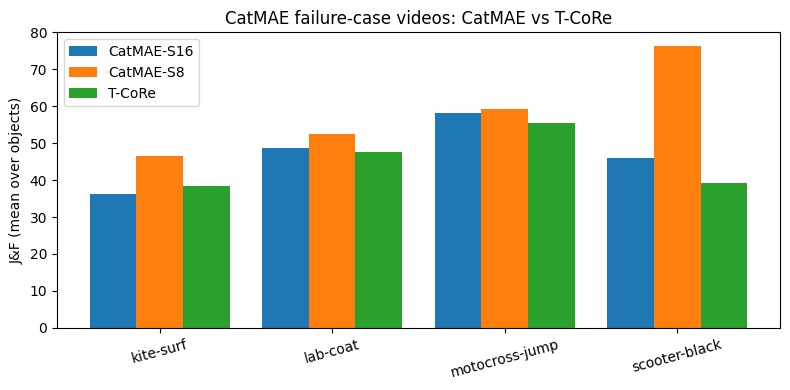

saved: ['comparison_catmae_vs_tcore.csv', 'failure_cases_catmae_vs_tcore.png', 'tcore_vits16_400ep_K400_global_results-val.csv', 'tcore_vits16_400ep_K400_per-sequence_results-val.csv']


In [7]:
# ===== Cell 7: T-CoRe vs CatMAE, per object (your CatMAE ViT-S/16 + ViT-S/8 reproduction numbers are embedded) =====
import io
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

CATMAE_CSV = """Sequence,J16,F16,J8,F8
bike-packing_1,0.406,0.572,0.495,0.683
bike-packing_2,0.679,0.659,0.765,0.778
blackswan_1,0.877,0.927,0.942,0.985
bmx-trees_1,0.283,0.675,0.285,0.635
bmx-trees_2,0.538,0.735,0.589,0.836
breakdance_1,0.676,0.678,0.684,0.693
camel_1,0.704,0.792,0.728,0.822
car-roundabout_1,0.864,0.793,0.891,0.809
car-shadow_1,0.898,0.937,0.897,0.874
cows_1,0.874,0.865,0.926,0.950
dance-twirl_1,0.796,0.802,0.850,0.880
dog_1,0.892,0.927,0.908,0.930
dogs-jump_1,0.130,0.255,0.506,0.709
dogs-jump_2,0.460,0.555,0.740,0.778
dogs-jump_3,0.718,0.841,0.823,0.899
drift-chicane_1,0.695,0.770,0.558,0.602
drift-straight_1,0.514,0.377,0.609,0.540
goat_1,0.835,0.835,0.835,0.818
gold-fish_1,0.717,0.646,0.741,0.730
gold-fish_2,0.594,0.627,0.763,0.854
gold-fish_3,0.789,0.845,0.831,0.876
gold-fish_4,0.810,0.882,0.823,0.840
gold-fish_5,0.864,0.819,0.884,0.888
horsejump-high_1,0.702,0.798,0.770,0.901
horsejump-high_2,0.567,0.777,0.661,0.852
india_1,0.843,0.806,0.882,0.861
india_2,0.593,0.585,0.632,0.620
india_3,0.574,0.557,0.513,0.511
judo_1,0.728,0.782,0.823,0.860
judo_2,0.700,0.713,0.765,0.780
kite-surf_1,0.222,0.262,0.280,0.393
kite-surf_2,0.250,0.257,0.256,0.274
kite-surf_3,0.475,0.705,0.671,0.923
lab-coat_1,0.000,0.000,0.000,0.000
lab-coat_2,0.000,0.000,0.000,0.000
lab-coat_3,0.866,0.791,0.907,0.859
lab-coat_4,0.845,0.748,0.892,0.805
lab-coat_5,0.815,0.806,0.889,0.883
libby_1,0.720,0.900,0.817,0.965
loading_1,0.878,0.805,0.924,0.907
loading_2,0.330,0.410,0.427,0.578
loading_3,0.620,0.674,0.668,0.725
mbike-trick_1,0.412,0.590,0.652,0.786
mbike-trick_2,0.618,0.658,0.725,0.727
motocross-jump_1,0.486,0.551,0.534,0.567
motocross-jump_2,0.663,0.624,0.614,0.652
paragliding-launch_1,0.793,0.885,0.799,0.879
paragliding-launch_2,0.465,0.760,0.615,0.855
paragliding-launch_3,0.013,0.045,0.029,0.160
parkour_1,0.813,0.899,0.892,0.961
pigs_1,0.809,0.771,0.843,0.827
pigs_2,0.582,0.743,0.659,0.803
pigs_3,0.901,0.868,0.941,0.931
scooter-black_1,0.109,0.370,0.654,0.839
scooter-black_2,0.683,0.680,0.793,0.762
shooting_1,0.220,0.246,0.234,0.252
shooting_2,0.747,0.752,0.756,0.742
shooting_3,0.684,0.903,0.749,0.926
soapbox_1,0.653,0.632,0.716,0.767
soapbox_2,0.254,0.368,0.604,0.666
soapbox_3,0.167,0.393,0.586,0.684
"""
cat = pd.read_csv(io.StringIO(CATMAE_CSV))
tc = pd.read_csv(RES / f"tcore_{VARIANT}_per-sequence_results-val.csv").rename(columns={"J-Mean": "Jt", "F-Mean": "Ft"})
df = cat.merge(tc, on="Sequence", how="inner")
assert len(cat) == len(tc) == len(df) == 61, f"object-count mismatch: CatMAE {len(cat)}, T-CoRe {len(tc)}, merged {len(df)}"
for k in ("16", "8", "t"):
    df[f"JF{k}"] = (df[f"J{k}"] + df[f"F{k}"]) / 2
df["video"] = df["Sequence"].str.rsplit("_", n=1).str[0]
df["delta_vs_S16"] = df["JFt"] - df["JF16"]

# ---- 1) global numbers (mean over the 61 objects = the official DAVIS J&F) ----
names = {"16": "CatMAE ViT-S/16", "8": "CatMAE ViT-S/8", "t": f"T-CoRe {VARIANT}"}
summary = pd.DataFrame({names[k]: [df[f"J{k}"].mean() * 100, df[f"F{k}"].mean() * 100, df[f"JF{k}"].mean() * 100] for k in names},
                       index=["J-Mean", "F-Mean", "J&F"]).round(2)
print("=== Global (DAVIS-2017 val) ===\n", summary.to_string(), "\n")
print(f"objects where T-CoRe beats CatMAE ViT-S/16: {(df.delta_vs_S16 > 0).sum()}/61 | "
      f"CatMAE ViT-S/8 is the finer-patch model, so ViT-S/16 is the like-for-like comparison\n")

# ---- 2) the CatMAE failure cases from your analysis ----
FAIL = {"lab-coat": "similar-looking objects", "kite-surf": "small object / large motion",
        "scooter-black": "small object / large motion", "motocross-jump": "small object / large motion"}
fc = df[df.video.isin(FAIL)][["Sequence", "JF16", "JF8", "JFt", "delta_vs_S16"]].copy()
fc[["JF16", "JF8", "JFt", "delta_vs_S16"]] = (fc[["JF16", "JF8", "JFt", "delta_vs_S16"]] * 100).round(1)
fc.columns = ["object", "CatMAE-S16", "CatMAE-S8", "T-CoRe", "T-CoRe - S16"]
print("=== Failure-case objects (J&F x100) ===\n", fc.to_string(index=False), "\n")
grp = (df[df.video.isin(FAIL)].groupby("video")[["JF16", "JF8", "JFt"]].mean() * 100).round(1)
grp.columns = ["CatMAE-S16", "CatMAE-S8", "T-CoRe"]
grp["failure mode"] = [FAIL[v] for v in grp.index]
print("=== Per failure-video mean (J&F x100) ===\n", grp.to_string(), "\n")

# ---- 3) biggest movers vs CatMAE ViT-S/16 ----
for title, sub in (("largest GAINS", df.nlargest(8, "delta_vs_S16")), ("largest LOSSES", df.nsmallest(8, "delta_vs_S16"))):
    t = sub[["Sequence", "JF16", "JFt", "delta_vs_S16"]].copy()
    t[["JF16", "JFt", "delta_vs_S16"]] = (t[["JF16", "JFt", "delta_vs_S16"]] * 100).round(1)
    t.columns = ["object", "CatMAE-S16", "T-CoRe", "delta"]
    print(f"=== {title} (T-CoRe vs CatMAE ViT-S/16, J&F x100) ===\n", t.to_string(index=False), "\n")

# ---- 4) save + plot ----
df.to_csv(RES / "comparison_catmae_vs_tcore.csv", index=False)
x = np.arange(len(grp)); w = 0.27
fig, ax = plt.subplots(figsize=(8, 4))
for i, col in enumerate(["CatMAE-S16", "CatMAE-S8", "T-CoRe"]):
    ax.bar(x + (i - 1) * w, grp[col], w, label=col)
ax.set_xticks(x); ax.set_xticklabels(grp.index, rotation=15); ax.set_ylabel("J&F (mean over objects)")
ax.set_title("CatMAE failure-case videos: CatMAE vs T-CoRe"); ax.legend(); plt.tight_layout()
plt.savefig(RES / "failure_cases_catmae_vs_tcore.png", dpi=150); plt.show()
print("saved:", sorted(p.name for p in RES.iterdir()))

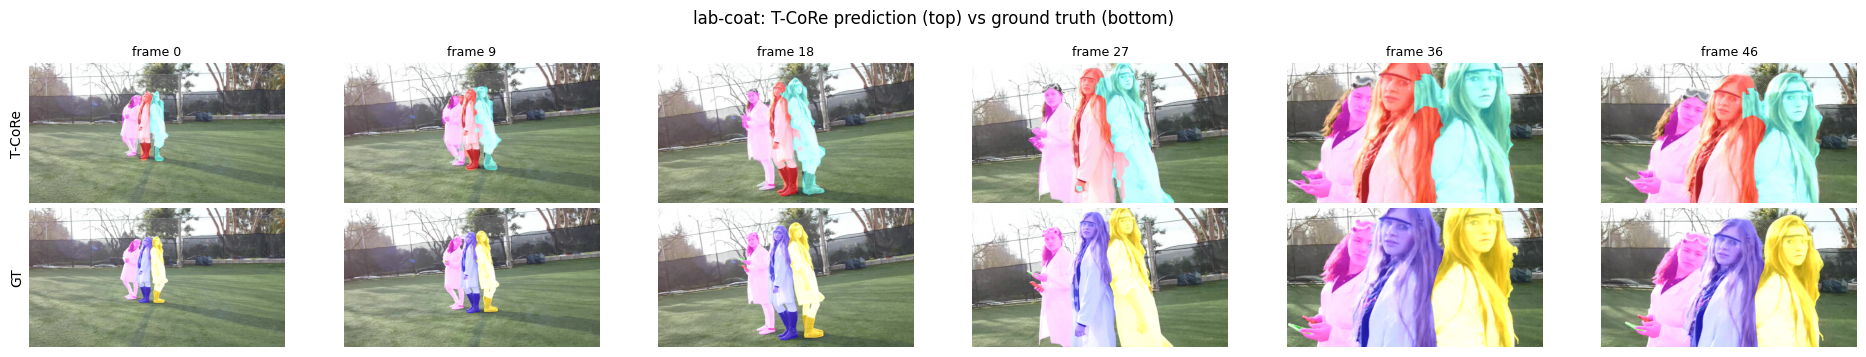

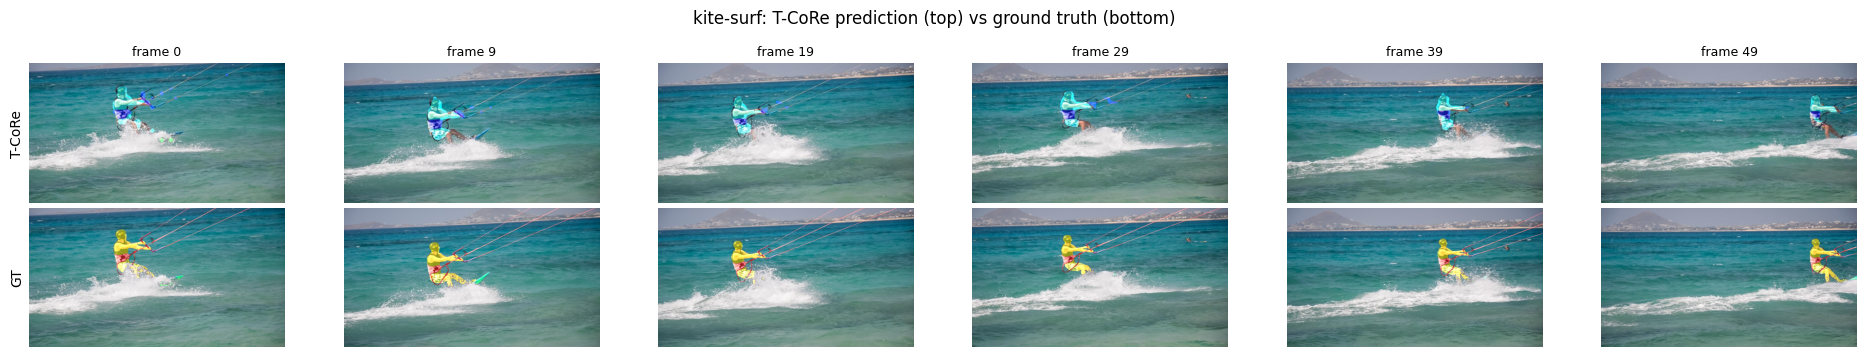

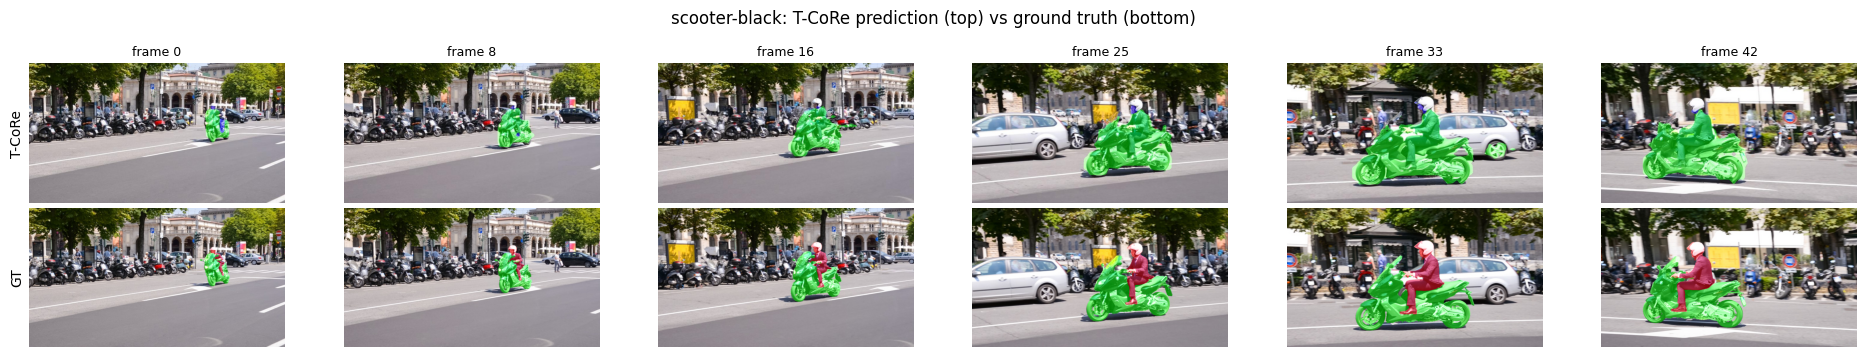

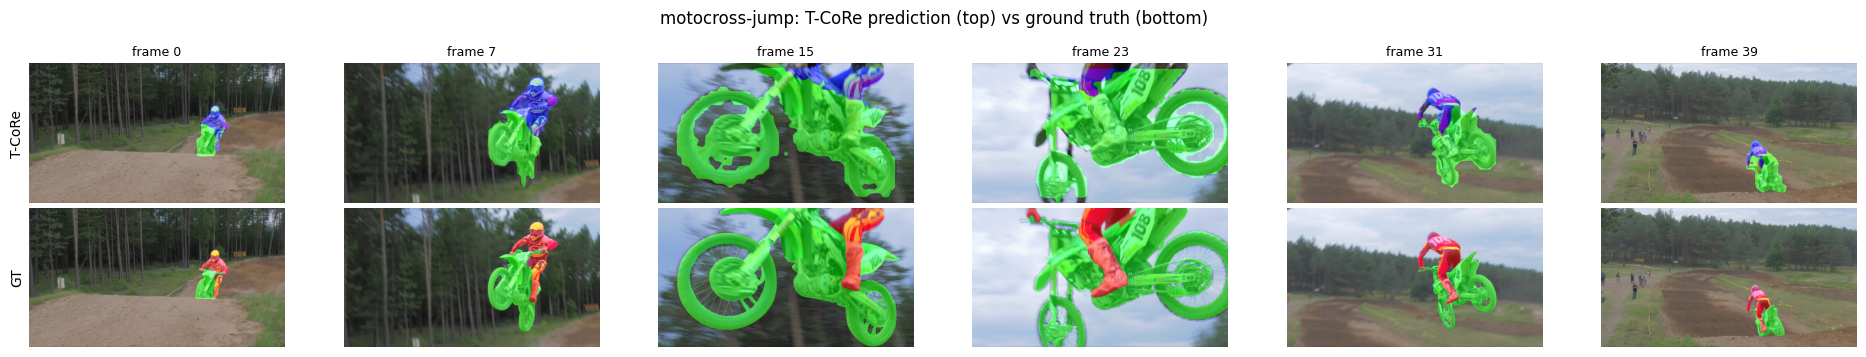

saved: ['kite-surf.png', 'lab-coat.png', 'motocross-jump.png', 'scooter-black.png']


In [8]:
# ===== Cell 8: qualitative contact sheets (prediction vs ground truth) for the failure videos =====
# Run right after cell 6/7 - the frames live in scratch space (/kaggle/temp) and vanish when the session ends.
import glob, os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

FAIL_VIDS = ["lab-coat", "kite-surf", "scooter-black", "motocross-jump"]
N_COLS = 6
QUAL = RES / "qualitative"
QUAL.mkdir(exist_ok=True)

def gt_blend(seq, t, size=(880, 480)):
    img = Image.open(f"{DAVIS_VAL}/JPEGImages/480p/{seq}/{t:05d}.jpg").convert("RGB").resize(size, Image.BILINEAR)
    lbl = Image.open(f"{DAVIS_VAL}/Annotations/480p/{seq}/{t:05d}.png").convert("RGB").resize(size, Image.NEAREST)
    return np.clip(np.asarray(img, np.float32) + np.asarray(lbl, np.float32), 0, 255).astype(np.uint8)   # same additive overlay as the pipeline

for seq in FAIL_VIDS:
    vid = VAL_SEQS.index(seq)                                      # prediction files are indexed by position in val.txt
    files = glob.glob(f"{OUT}/davis/in/{vid}_*_blend.jpg")
    ts = sorted(int(os.path.basename(f).split("_")[1]) for f in files)
    assert ts, f"no predictions found for {seq} (index {vid})"
    pick = sorted(set(np.linspace(0, len(ts) - 1, N_COLS).astype(int)))
    fig, axs = plt.subplots(2, len(pick), figsize=(3.2 * len(pick), 3.6), squeeze=False)
    for j, k in enumerate(pick):
        t = ts[k]
        axs[0, j].imshow(np.asarray(Image.open(f"{OUT}/davis/in/{vid}_{t}_blend.jpg")))
        axs[1, j].imshow(gt_blend(seq, t))
        axs[0, j].set_title(f"frame {t}", fontsize=9)
        for r in (0, 1):
            axs[r, j].axis("off")
    axs[0, 0].text(-0.02, 0.5, "T-CoRe", transform=axs[0, 0].transAxes, rotation=90, ha="right", va="center")
    axs[1, 0].text(-0.02, 0.5, "GT", transform=axs[1, 0].transAxes, rotation=90, ha="right", va="center")
    fig.suptitle(f"{seq}: T-CoRe prediction (top) vs ground truth (bottom)")
    plt.tight_layout()
    plt.savefig(QUAL / f"{seq}.png", dpi=110)
    plt.show()
    plt.close(fig)
print("saved:", sorted(p.name for p in QUAL.iterdir()))

In [9]:
# ===== Cell 9: controlled experiment - SAME T-CoRe ViT-S/16 weights, several input resolutions =====
# Runs every resolution in RUN_CROPS that has no saved result yet (so already-finished runs are skipped).
# 720x1312 -> 45x82 token grid | 960x1760 -> 60x110 token grid (= the grid CatMAE ViT-S/8 uses at 480x880).
# Needs cells 1-6 and the current cell 4 (memory-lean driver). If a stage dies with 'Killed': lower KEY_CHUNK (4, then 2).
import shutil

RUN_CROPS = [(720, 1312), (960, 1760)]
KEY_CHUNK = 8                                        # target frames per affinity chunk (even); lower = less host RAM
FORCE = False                                        # True = recompute even if the result CSV already exists

for CROP in RUN_CROPS:
    TAG = f"{VARIANT}_{CROP[0]}x{CROP[1]}"
    OUT2 = TEMP / "tcore_runs" / TAG
    RADIUS = round(20 * CROP[0] / 480)               # keeps the same physical search window (20 tokens at 480 px high)
    if (RES / f"tcore_{TAG}_per-sequence_results-val.csv").exists() and not FORCE:
        print(f"[skip] {CROP[0]}x{CROP[1]}: result already in {RES}")
        continue
    print(f"\n########## {CROP[0]}x{CROP[1]} | radius {RADIUS} ##########")

    def drv2(stage, TAG=TAG, OUT2=OUT2, CROP=CROP, RADIUS=RADIUS):      # later duplicate flags override the ones set in drv()
        return drv(stage, "--tag", TAG, "--out", str(OUT2), "--crop", str(CROP[0]), str(CROP[1]),
                   "--radius", str(RADIUS), "--batch_size", "1", "--key_chunk", str(KEY_CHUNK))

    run_stream(drv2("check"))
    run_stream(drv2("prop"))        # prints peak host RAM after every video - tell me the last line if it dies
    run_stream(drv2("eval"))
    for f in OUT2.glob(f"tcore_{TAG}_*.csv"):
        shutil.copy(f, RES / f.name)
    print("saved:", sorted(p.name for p in RES.glob(f"tcore_{TAG}_*")))

print("\nresolutions available in", RES, ":", sorted(p.name.split(f"tcore_{VARIANT}_")[1].split("_per-sequence")[0]
                                                      for p in RES.glob(f"tcore_{VARIANT}_*x*_per-sequence_results-val.csv")))


########## 720x1312 | radius 30 ##########
$ /usr/bin/python3 -u -W ignore /kaggle/working/run_tcore_davis.py --stage ...
[env] python 3.13.16 | torch 2.11.0+cu130 | numpy 2.1.3 | cv2 4.14.0
[env] device: cuda Tesla T4
[data] 30 sequences, 1999 frames, 1999 annotation PNGs
[ckpt] file: /tmp/tcore_ckpt/vits16_400ep_K400.pth | top-level: ['teacher']
[ckpt] unwrapping 'teacher'
[ckpt] matched 176/176 model tensors | unexpected (ignored, e.g. heads): 8
[ckpt] weights loaded OK
[model] vit_small | patch 16 | embed_dim 384 | registers 4 | params 21.7M
[model] forward OK -> (1, 3691, 384) (cls + 45x82 patch tokens)
[data] first video OK: bike-packing frames=69 imgs=(89, 3, 720, 1312) lbl_grid=(89, 45, 82, 3) colours(bg+objs)=3 (9.9s)
PREFLIGHT OK
$ /usr/bin/python3 -u -W ignore /kaggle/working/run_tcore_davis.py --stage ...
[ckpt] file: /tmp/tcore_ckpt/vits16_400ep_K400.pth | top-level: ['teacher']
[ckpt] unwrapping 'teacher'
[ckpt] matched 176/176 model tensors | unexpected (ignored, e.g. h

=== Global (DAVIS-2017 val), x100 ===
                 J-Mean  F-Mean    J&F
CatMAE-S16        59.69   65.46  62.57
CatMAE-S8         67.61   73.59  70.60
T-CoRe            63.48   66.03  64.75
T-CoRe 720x1312   67.31   72.71  70.01
T-CoRe 960x1760   68.86   73.71  71.29 

=== Failure videos, mean J&F x100 ===
                 CatMAE-S16  CatMAE-S8  T-CoRe  T-CoRe 720x1312  T-CoRe 960x1760
video                                                                          
kite-surf             36.2       46.6    38.5             47.3             47.9
lab-coat              48.7       52.4    47.7             50.5             51.6
motocross-jump        58.1       59.2    55.5             61.2             64.1
scooter-black         46.1       76.2    39.3             64.1             70.0 

=== Failure objects, J&F x100 ===
                   CatMAE-S16  CatMAE-S8  T-CoRe  T-CoRe 720x1312  T-CoRe 960x1760
Sequence                                                                         
kite-s

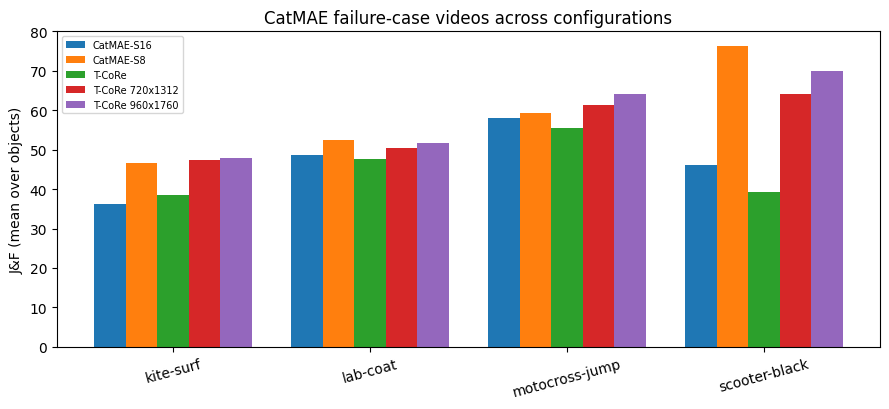

saved: /kaggle/working/tcore_results/comparison_all_configs.csv and /kaggle/working/tcore_results/failure_cases_all_configs.png


In [10]:
# ===== Cell 10: CatMAE (S/16, S/8) vs T-CoRe at native resolution and at every higher resolution in tcore_results =====
# Needs the CSV written by cell 7 and the hi-res CSVs written by cell 9. Works after a session restart.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = pd.read_csv(RES / "comparison_catmae_vs_tcore.csv")                       # cell 7: CatMAE + native T-CoRe, 61 objects
FAIL = {"lab-coat": "2 sub-patch objects (0.0) + 3 look-alikes", "kite-surf": "small object / large motion",
        "scooter-black": "small object / large motion", "motocross-jump": "small object / large motion"}
cfg = {"CatMAE-S16": ("J16", "F16"), "CatMAE-S8": ("J8", "F8"), "T-CoRe": ("Jt", "Ft")}
d = base[["Sequence", "video"] + [c for pair in cfg.values() for c in pair]].copy()

runs = []
for f in sorted(RES.glob(f"tcore_{VARIANT}_*x*_per-sequence_results-val.csv")):
    tag = f.name.split(f"tcore_{VARIANT}_")[1].split("_per-sequence")[0]
    runs.append((int(tag.split("x")[0]), tag, f))
for _, tag, f in sorted(runs):
    t = pd.read_csv(f).set_index("Sequence")
    d[f"J_{tag}"], d[f"F_{tag}"] = d["Sequence"].map(t["J-Mean"]), d["Sequence"].map(t["F-Mean"])
    assert d[f"J_{tag}"].notna().all(), f"{tag}: objects missing"
    cfg[f"T-CoRe {tag}"] = (f"J_{tag}", f"F_{tag}")
assert len(d) == 61, len(d)
for n, (j, f_) in cfg.items():
    d[f"JF_{n}"] = (d[j] + d[f_]) / 2
names = list(cfg)

print("=== Global (DAVIS-2017 val), x100 ===")
print(pd.DataFrame({n: [d[cfg[n][0]].mean() * 100, d[cfg[n][1]].mean() * 100, d[f"JF_{n}"].mean() * 100] for n in names},
                   index=["J-Mean", "F-Mean", "J&F"]).round(2).T.to_string(), "\n")

fv = d[d.video.isin(FAIL)]
g = (fv.groupby("video")[[f"JF_{n}" for n in names]].mean() * 100).round(1)
g.columns = names
print("=== Failure videos, mean J&F x100 ===\n", g.to_string(), "\n")
o = (fv.set_index("Sequence")[[f"JF_{n}" for n in names]] * 100).round(1)
o.columns = names
print("=== Failure objects, J&F x100 ===\n", o.to_string(), "\n")

print("=== vs native T-CoRe: objects improved / mean change in J&F points ===")
for n in names[3:]:
    dlt = (d[f"JF_{n}"] - d["JF_T-CoRe"]) * 100
    print(f"  {n:20s} {(dlt > 0).sum():2d}/61 improved | mean {dlt.mean():+.2f} | worst object {d.loc[dlt.idxmin(), 'Sequence']} ({dlt.min():+.1f})")

d.to_csv(RES / "comparison_all_configs.csv", index=False)
x = np.arange(len(g)); w = 0.8 / len(names)
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, n in enumerate(names):
    ax.bar(x + (i - (len(names) - 1) / 2) * w, g[n], w, label=n)
ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=15); ax.set_ylabel("J&F (mean over objects)")
ax.set_title("CatMAE failure-case videos across configurations"); ax.legend(fontsize=7); plt.tight_layout()
plt.savefig(RES / "failure_cases_all_configs.png", dpi=150); plt.show()
print("saved:", RES / "comparison_all_configs.csv", "and", RES / "failure_cases_all_configs.png")

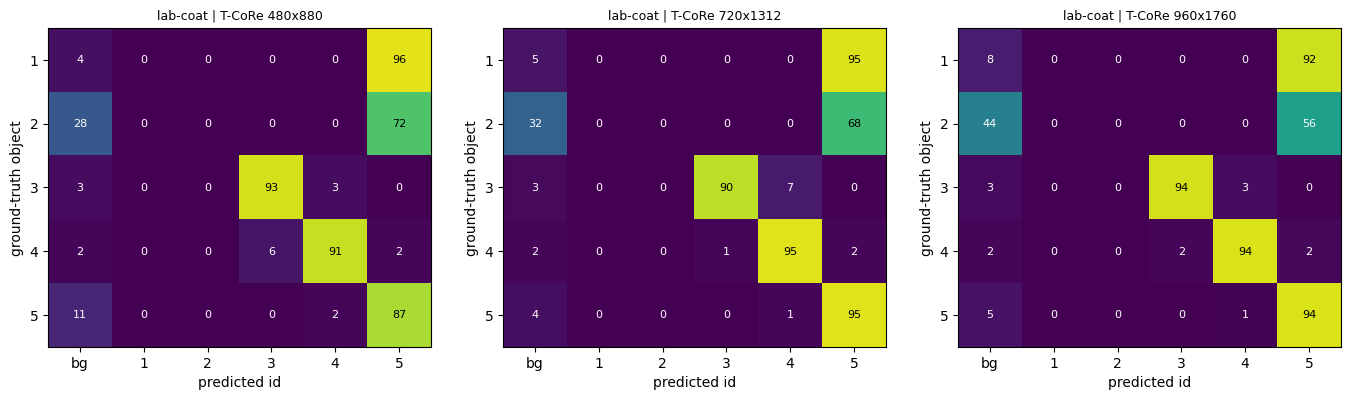

lab-coat | T-CoRe 480x880
   GT object 1:  0.0% own id |  4.2% background | largest wrong id = 5 (95.8%)   <-- mostly assigned to another object
   GT object 2:  0.0% own id | 27.7% background | largest wrong id = 5 (72.3%)   <-- mostly assigned to another object
   GT object 3: 93.4% own id |  3.1% background | largest wrong id = 4 (3.4%)
   GT object 4: 91.1% own id |  1.7% background | largest wrong id = 3 (5.6%)
   GT object 5: 87.5% own id | 10.8% background | largest wrong id = 4 (1.7%)
lab-coat | T-CoRe 720x1312
   GT object 1:  0.0% own id |  5.3% background | largest wrong id = 5 (94.7%)   <-- mostly assigned to another object
   GT object 2:  0.0% own id | 31.6% background | largest wrong id = 5 (68.4%)   <-- mostly assigned to another object
   GT object 3: 90.1% own id |  2.6% background | largest wrong id = 4 (7.3%)
   GT object 4: 95.1% own id |  1.8% background | largest wrong id = 5 (1.6%)
   GT object 5: 95.0% own id |  3.6% background | largest wrong id = 4 (1.4%)
lab

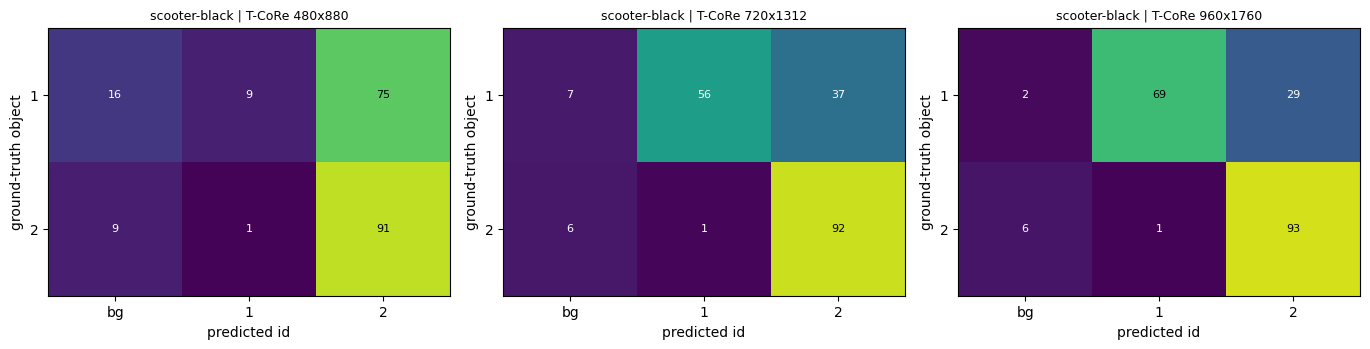

scooter-black | T-CoRe 480x880
   GT object 1:  8.9% own id | 16.2% background | largest wrong id = 2 (74.9%)   <-- mostly assigned to another object
   GT object 2: 90.6% own id |  8.6% background | largest wrong id = 1 (0.9%)
scooter-black | T-CoRe 720x1312
   GT object 1: 55.8% own id |  7.1% background | largest wrong id = 2 (37.1%)
   GT object 2: 92.1% own id |  6.5% background | largest wrong id = 1 (1.5%)
scooter-black | T-CoRe 960x1760
   GT object 1: 68.7% own id |  2.4% background | largest wrong id = 2 (28.9%)
   GT object 2: 93.4% own id |  5.6% background | largest wrong id = 1 (1.0%)
saved: ['confusion_lab-coat.png', 'confusion_scooter-black.png']


In [11]:
# ===== Cell 11: identity-confusion diagnosis - where do the pixels of each ground-truth object end up? =====
# CPU only, ~1 min. Reads the converted predictions of the runs that are still on disk (scratch space).
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

QUAL = RES / "qualitative"            # same folder as cell 8
QUAL.mkdir(exist_ok=True)

DIAG_VIDS = ["lab-coat", "scooter-black"]                  # add "kite-surf", "motocross-jump" if you want them too
RUNS = {"T-CoRe 480x880": OUT}
for d_ in sorted((TEMP / "tcore_runs").glob(f"{VARIANT}_*x*"), key=lambda p: int(p.name.split("_")[-1].split("x")[0])):
    if (d_ / "davis" / "out").exists():                        # every high-resolution run still on disk
        RUNS[f"T-CoRe {d_.name.split('_')[-1]}"] = d_

def confusion(seq, run_dir):
    gts = sorted((DAVIS_VAL / "Annotations" / "480p" / seq).glob("*.png"))
    pr_dir = run_dir / "davis" / "out" / seq
    K = int(np.array(Image.open(gts[0])).max())            # number of objects (first frame)
    frac = np.zeros((K, K + 1)); n = np.zeros(K)
    for t in range(1, len(gts) - 1):                       # DAVIS scoring skips the first and last frame
        g = np.array(Image.open(gts[t]))
        p = np.array(Image.open(pr_dir / f"{t:05d}.png"))
        assert g.shape == p.shape, (g.shape, p.shape)
        for o in range(1, K + 1):
            gm = g == o
            if gm.any():
                n[o - 1] += 1
                frac[o - 1] += np.bincount(p[gm].ravel(), minlength=K + 1)[:K + 1] / gm.sum()
    return frac / np.maximum(n, 1)[:, None]                # rows: GT object 1..K | cols: predicted id 0 (background), 1..K

def describe(frac):
    for o in range(frac.shape[0]):
        row = frac[o].copy()
        own, bg = row[o + 1], row[0]
        row[o + 1] = row[0] = -1
        wrong = int(row.argmax())
        print(f"   GT object {o + 1}: {own:5.1%} own id | {bg:5.1%} background | "
              f"largest wrong id = {wrong} ({frac[o, wrong]:.1%})" + ("   <-- mostly assigned to another object" if frac[o, wrong] > own and frac[o, wrong] > bg else ""))

for seq in DIAG_VIDS:
    mats = {name: confusion(seq, d) for name, d in RUNS.items()}
    fig, axs = plt.subplots(1, len(mats), figsize=(4.6 * len(mats), 3.8), squeeze=False)
    for ax, (name, m) in zip(axs[0], mats.items()):
        ax.imshow(m, vmin=0, vmax=1, cmap="viridis")
        ax.set_xticks(range(m.shape[1])); ax.set_xticklabels(["bg"] + [str(i) for i in range(1, m.shape[1])])
        ax.set_yticks(range(m.shape[0])); ax.set_yticklabels([str(i) for i in range(1, m.shape[0] + 1)])
        ax.set_xlabel("predicted id"); ax.set_ylabel("ground-truth object"); ax.set_title(f"{seq} | {name}", fontsize=9)
        for i in range(m.shape[0]):
            for j in range(m.shape[1]):
                ax.text(j, i, f"{m[i, j] * 100:.0f}", ha="center", va="center", fontsize=8, color="w" if m[i, j] < 0.6 else "k")
    plt.tight_layout()
    plt.savefig(QUAL / f"confusion_{seq}.png", dpi=120)
    plt.show(); plt.close(fig)
    for name, m in mats.items():
        print(f"{seq} | {name}")
        describe(m)
print("saved:", sorted(p.name for p in QUAL.glob("confusion_*")))

In [12]:
# ===== Cell 12: can the label grid even represent each object? (CPU, seconds, no model) =====
# The propagation starts from the first-frame labels shrunk to the token grid with cv2.INTER_LINEAR (no averaging).
# This checks, per object, whether it survives that step, and compares with a faithful area-averaged shrink.
import cv2
import numpy as np
from PIL import Image

DIAG_SEQS = ["lab-coat", "scooter-black"]
DIAG_CROPS = [(480, 880), (720, 1312)]
PATCH = 16

def grid_stats(ids, K, crop, interp):
    h, w = crop
    ids = cv2.resize(ids, (w, h), interpolation=cv2.INTER_NEAREST)                       # same as the dataset: labels follow the image resize
    onehot = np.stack([ids == k for k in range(K + 1)], axis=-1).astype(np.float32)
    gh, gw = int(np.ceil(h / PATCH)), int(np.ceil(w / PATCH))
    g = cv2.resize(onehot, (gw, gh), interpolation=interp)                               # the shrink to the token grid
    win = np.bincount(g.argmax(-1).ravel(), minlength=K + 1)                              # grid cells in which each id has the largest value
    return g, win, g.reshape(-1, K + 1).max(0)

def verdict(win_lin, win_area):
    if win_lin > 0:
        return "present in the grid -> a failure here is model-side (ambiguity / absorption)"
    if win_area > 0:
        return "LOST by INTER_LINEAR downsampling (a faithful shrink would keep it)"
    return "sub-patch object: no grid cell is majority-owned even with averaging"

for seq in DIAG_SEQS:
    gts = sorted((DAVIS_VAL / "Annotations" / "480p" / seq).glob("*.png"))
    first = np.array(Image.open(gts[0]))
    K = int(first.max())
    areas = np.array([[(np.array(Image.open(f)) == k).sum() for k in range(1, K + 1)] for f in gts[::5]])   # every 5th frame
    print(f"\n=== {seq}: {len(gts)} frames, {K} objects ===")
    for crop in DIAG_CROPS:
        gl, wl, pl = grid_stats(first, K, crop, cv2.INTER_LINEAR)
        ga, wa, pa = grid_stats(first, K, crop, cv2.INTER_AREA)
        print(f"-- input {crop[0]}x{crop[1]}, token grid {gl.shape[0]}x{gl.shape[1]}")
        print("   obj | GT px frame0 (median over frames) | cells won LINEAR | peak LINEAR | cells won AREA")
        for k in range(1, K + 1):
            print(f"    {k}  | {int((first == k).sum()):6d} ({int(np.median(areas[:, k - 1])):6d})              | {wl[k]:4d}             | {pl[k]:.2f}        | {wa[k]:4d}   -> {verdict(wl[k], wa[k])}")


=== lab-coat: 47 frames, 5 objects ===
-- input 480x880, token grid 30x55
   obj | GT px frame0 (median over frames) | cells won LINEAR | peak LINEAR | cells won AREA
    1  |     18 (   321)              |    0             | 0.00        |    0   -> sub-patch object: no grid cell is majority-owned even with averaging
    2  |     14 (   119)              |    0             | 0.00        |    0   -> sub-patch object: no grid cell is majority-owned even with averaging
    3  |   8196 ( 38907)              |   35             | 1.00        |   35   -> present in the grid -> a failure here is model-side (ambiguity / absorption)
    4  |   8641 ( 38962)              |   34             | 1.00        |   34   -> present in the grid -> a failure here is model-side (ambiguity / absorption)
    5  |   8197 ( 27211)              |   32             | 1.00        |   36   -> present in the grid -> a failure here is model-side (ambiguity / absorption)
-- input 720x1312, token grid 45x82
   obj | GT 

configurations: ['CatMAE-S16', 'CatMAE-S8', 'T-CoRe', 'T-CoRe 720x1312', 'T-CoRe 960x1760']

=== global J&F x100 per configuration ===
CatMAE-S16         62.57
CatMAE-S8          70.60
T-CoRe             64.75
T-CoRe 720x1312    70.01
T-CoRe 960x1760    71.29

=== Spearman correlation: object size in tokens (frame 0) vs J&F ===
  CatMAE-S16             rho = +0.66  (p = 7e-09, n = 61)
  CatMAE-S8              rho = +0.57  (p = 2e-06, n = 61)
  T-CoRe                 rho = +0.66  (p = 7e-09, n = 61)
  T-CoRe 720x1312        rho = +0.58  (p = 1e-06, n = 61)
  T-CoRe 960x1760        rho = +0.47  (p = 0.0001, n = 61)

=== mean J&F x100 by object size in tokens (each configuration uses its OWN token grid) ===
       CatMAE-S16  CatMAE-S16 (n)  CatMAE-S8  CatMAE-S8 (n)  T-CoRe  T-CoRe (n)  T-CoRe 720x1312  T-CoRe 720x1312 (n)  T-CoRe 960x1760  T-CoRe 960x1760 (n)
0             0.0               2        0.0              1     0.0           2              0.0                    2             

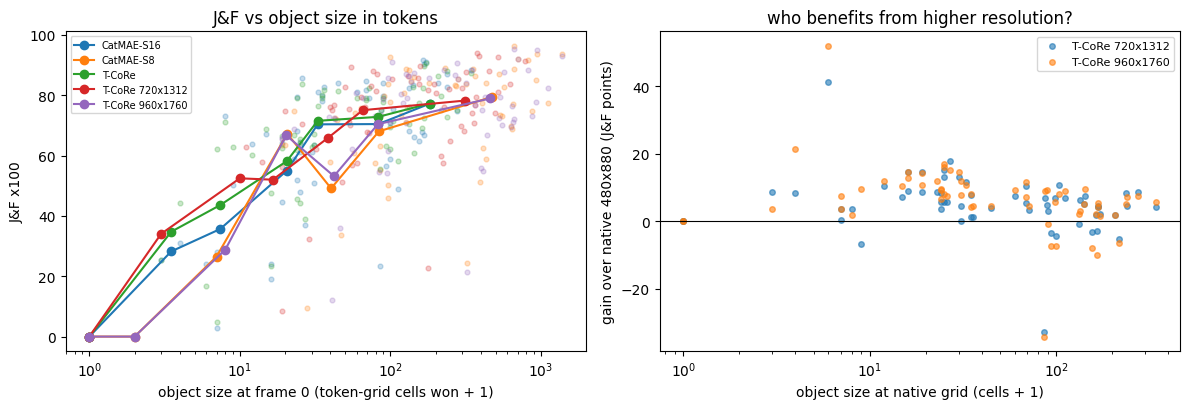

saved: /kaggle/working/tcore_results/size_vs_jf.png and /kaggle/working/tcore_results/comparison_all_configs_with_sizes.csv


In [13]:
# ===== Cell 13: does an object's size IN TOKENS explain J&F? All 61 objects, every configuration found (CPU, ~1 min) =====
# Needs cell 7's comparison_catmae_vs_tcore.csv (CatMAE + native T-CoRe columns), DAVIS_VAL from cell 2, and any T-CoRe high-resolution
# per-sequence CSVs already saved in RES by cell 9 (e.g. ..._720x1312_... and ..._960x1760_...): all of them are picked up.
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import spearmanr

d = pd.read_csv(RES / "comparison_catmae_vs_tcore.csv")[["Sequence", "video", "JF16", "JF8", "JFt"]]       # written by cell 7
CONFIGS = {                                                       # name -> (J&F column, input size, patch size)
    "CatMAE-S16": ("JF16", (480, 880), 16),
    "CatMAE-S8":  ("JF8",  (480, 880), 8),
    "T-CoRe":     ("JFt",  (480, 880), 16),
}
HIRES = []
for f in sorted(RES.glob(f"tcore_{VARIANT}_*x*_per-sequence_results-val.csv")):
    tag = f.name.split(f"tcore_{VARIANT}_")[1].split("_per-sequence")[0]                # e.g. 960x1760
    H, W = (int(v) for v in tag.split("x"))
    t = pd.read_csv(f).set_index("Sequence")
    d[f"JF_{tag}"] = d["Sequence"].map((t["J-Mean"] + t["F-Mean"]) / 2)
    assert d[f"JF_{tag}"].notna().all() and len(t) == len(d) == 61, f"{f.name}: object mismatch"
    CONFIGS[f"T-CoRe {tag}"] = (f"JF_{tag}", (H, W), 16)
    HIRES.append(f"T-CoRe {tag}")
print("configurations:", list(CONFIGS))

def cells_won(first, K, crop, patch):
    """token-grid cells in which each id wins the argmax, using the protocol's own INTER_LINEAR shrink"""
    h, w = crop
    ids = cv2.resize(first, (w, h), interpolation=cv2.INTER_NEAREST)
    onehot = np.stack([ids == k for k in range(K + 1)], axis=-1).astype(np.float32)
    g = cv2.resize(onehot, (int(np.ceil(w / patch)), int(np.ceil(h / patch))), interpolation=cv2.INTER_LINEAR)
    return np.bincount(g.argmax(-1).ravel(), minlength=K + 1)

first_cache = {}
for name, (col, crop, patch) in CONFIGS.items():
    vals = []
    for seq_obj in d["Sequence"]:
        seq, k = seq_obj.rsplit("_", 1)
        if seq not in first_cache:
            first_cache[seq] = np.array(Image.open(sorted((DAVIS_VAL / "Annotations" / "480p" / seq).glob("*.png"))[0]))
        first = first_cache[seq]
        vals.append(int(cells_won(first, int(first.max()), crop, patch)[int(k)]))
    d[f"cells_{name}"] = vals

BINS = [0, 1, 5, 10, 25, 50, 100, 10_000]
LABELS = ["0", "1-4", "5-9", "10-24", "25-49", "50-99", "100+"]
print("\n=== global J&F x100 per configuration ===")
print(pd.Series({n: round(d[c].mean() * 100, 2) for n, (c, _, _) in CONFIGS.items()}).to_string())

print("\n=== Spearman correlation: object size in tokens (frame 0) vs J&F ===")
for name, (col, _, _) in CONFIGS.items():
    rho, p = spearmanr(d[f"cells_{name}"], d[col])
    print(f"  {name:22s} rho = {rho:+.2f}  (p = {p:.1g}, n = {len(d)})")

print("\n=== mean J&F x100 by object size in tokens (each configuration uses its OWN token grid) ===")
rows = {}
for name, (col, _, _) in CONFIGS.items():
    b = pd.cut(d[f"cells_{name}"], BINS, labels=LABELS, right=False)
    rows[name] = (d.groupby(b, observed=False)[col].mean() * 100).round(1)
    rows[name + " (n)"] = d.groupby(b, observed=False)[col].size()
print(pd.DataFrame(rows).to_string())

bn = pd.cut(d["cells_T-CoRe"], BINS, labels=LABELS, right=False)
gains = {}
for name in HIRES:
    d[f"gain_{name}"] = (d[CONFIGS[name][0]] - d["JFt"]) * 100
    gains[name] = d.groupby(bn, observed=False)[f"gain_{name}"].mean().round(1)
if HIRES:
    gains["n"] = d.groupby(bn, observed=False).size()
    print("\n=== T-CoRe: mean gain over native 480x880 (J&F points) by NATIVE object size in tokens ===")
    print(pd.DataFrame(gains).to_string())

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for name, (col, _, _) in CONFIGS.items():
    axs[0].scatter(d[f"cells_{name}"] + 1, d[col] * 100, s=12, alpha=0.25)
    b = pd.cut(d[f"cells_{name}"], BINS, labels=LABELS, right=False)
    g = d.groupby(b, observed=False).agg(x=(f"cells_{name}", lambda s: s.mean() + 1), y=(col, "mean")).dropna()
    axs[0].plot(g["x"], g["y"] * 100, marker="o", label=name)
axs[0].set_xscale("log"); axs[0].set_xlabel("object size at frame 0 (token-grid cells won + 1)"); axs[0].set_ylabel("J&F x100")
axs[0].set_title("J&F vs object size in tokens"); axs[0].legend(fontsize=7)
for name in HIRES:
    axs[1].scatter(d["cells_T-CoRe"] + 1, d[f"gain_{name}"], s=16, alpha=0.6, label=name)
axs[1].axhline(0, color="k", lw=0.8); axs[1].set_xscale("log")
axs[1].set_xlabel("object size at native grid (cells + 1)"); axs[1].set_ylabel("gain over native 480x880 (J&F points)")
axs[1].set_title("who benefits from higher resolution?"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RES / "size_vs_jf.png", dpi=140); plt.show()
d.to_csv(RES / "comparison_all_configs_with_sizes.csv", index=False)
print("saved:", RES / "size_vs_jf.png", "and", RES / "comparison_all_configs_with_sizes.csv")